In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.lines as mlines

from transform_data import get_transformed_data, get_shock_mask
from field_config import field_lims, field_labels, field_scales

import flash_amr_tools
import h5py

In [2]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]


# list of fields we want to plot 1D slice of
fields = ["dens", "temp", "vel"]

times = [150, 300, 500] * u.kyr
times_lss = ["-", "--", ":"]

In [3]:
def get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns):

    field_slice = flash_amr_tools.get_slice(
        field_data,
        pos=0.0,
        axis=2,
        ref_lvl=ref_lvl,
        bbox=bbox,
        bsize=bsize,
        brefs=brefs,
        bns=bns,
    )
    # find zero value of y since we cannot slice again
    y_idx = np.digitize(0.0, yarr, right=True)
    return field_slice[:, y_idx]

starISM_hdf5_plt_cnt_0015
minimum position of the region of interest:  [-6.17135516e+19 -1.54283879e+20 -7.71419395e+19]
maximum position of the region of interest:  [9.25703274e+19 1.54283879e+20 7.71419395e+19]
Finding all leaf blocks in given region
13120 13120
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  8.0 16.0 8.0
Block shape:  (8, 16, 8)
Total number of blocks including parent blocks: 14848
Region extended to:	lower		upper
	x	-6.17135514e+19		+9.25703293e+19
	y	-1.54283876e+20		+1.54283876e+20
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+1.54283889e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+1.54283879e+19	+0.00000000e+00	+0.00000000e+00
List of variables in file: ['active', 'amass', 'bflags', 

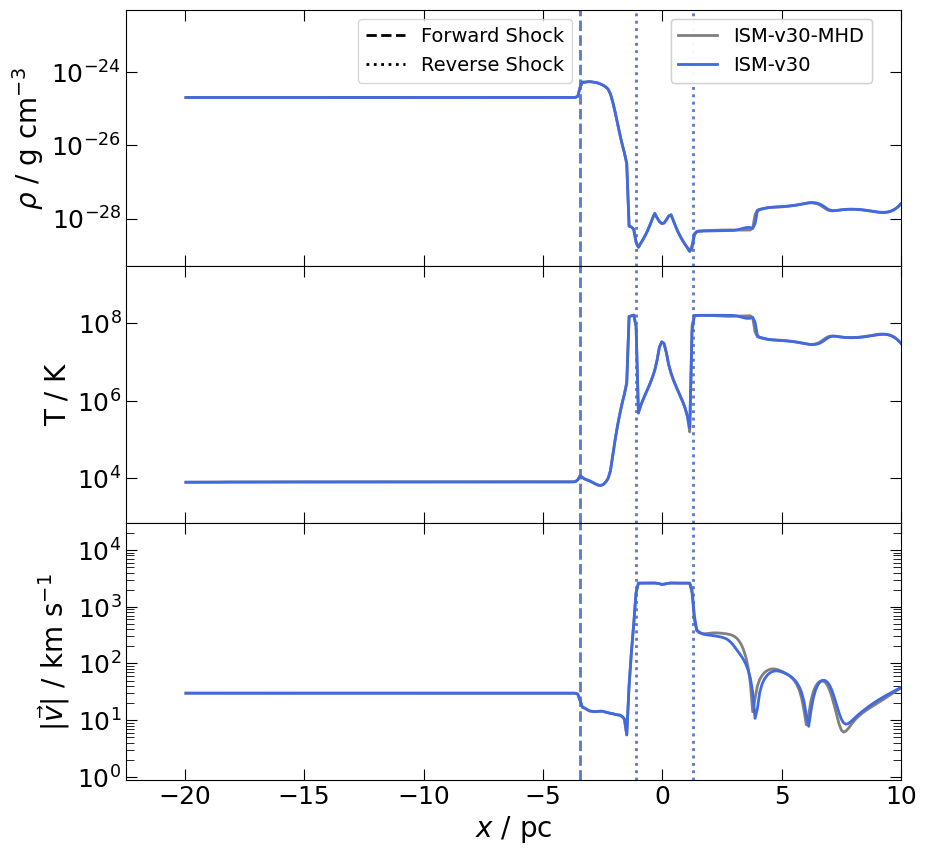

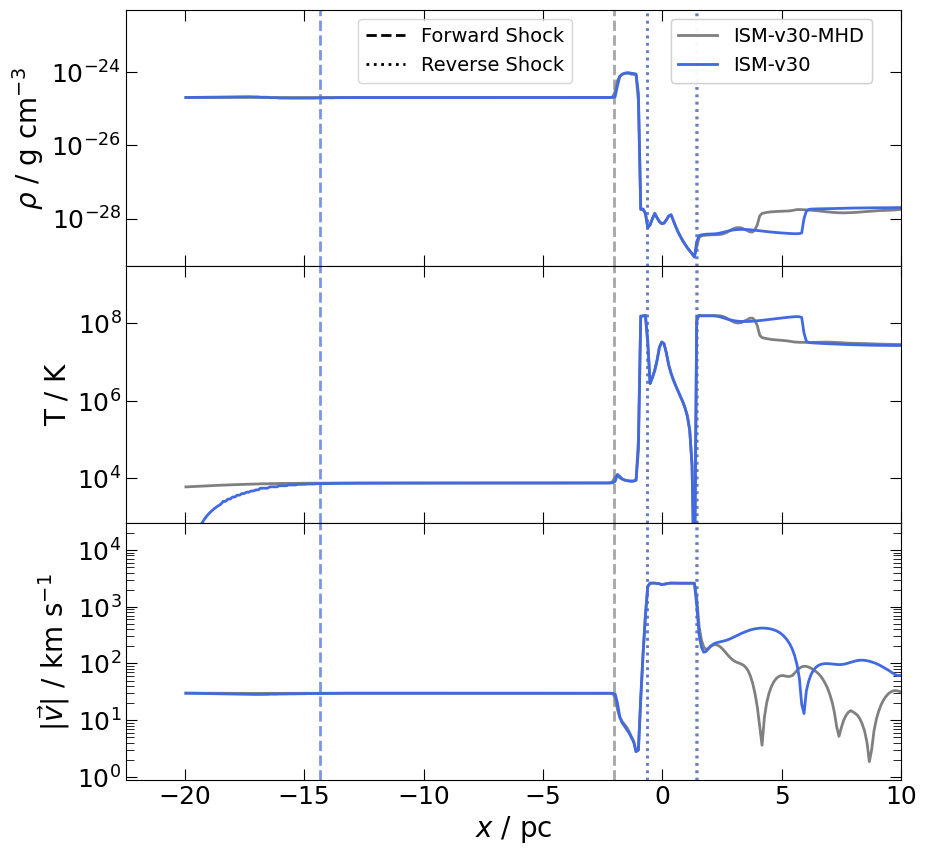

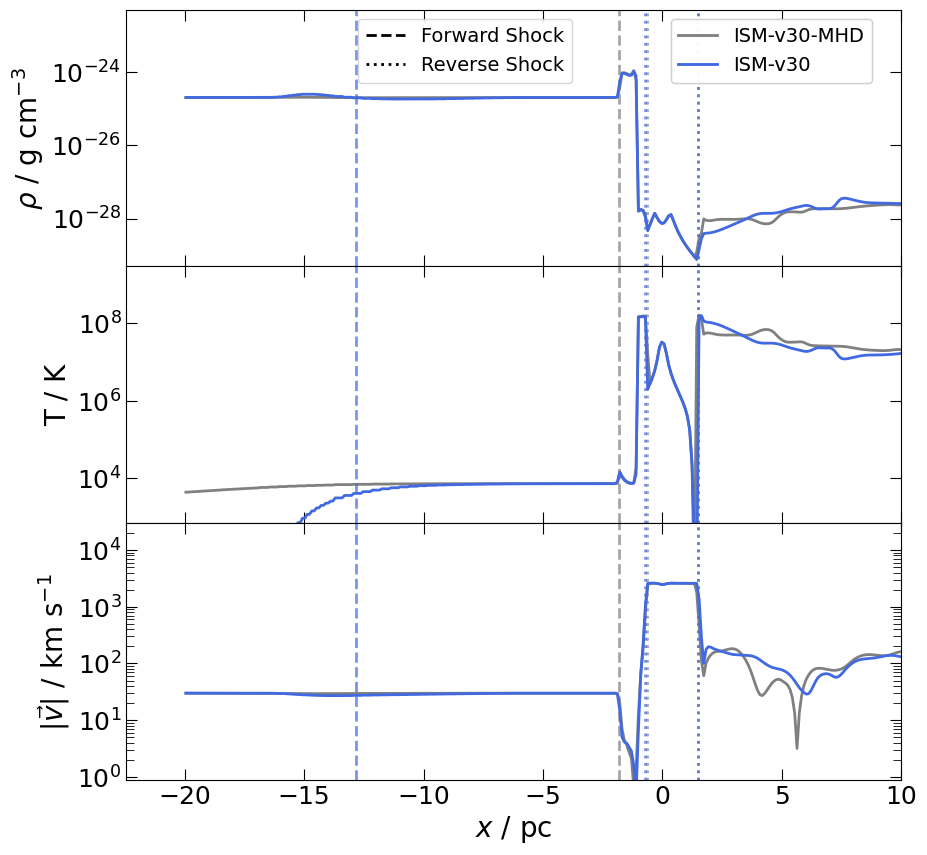

In [4]:
# legend handles

# time_handles = []
# initial parameters
for it, time in enumerate(times):

    fig = plt.figure(figsize=(10,10))
    gs = fig.add_gridspec(len(fields), 1, hspace=0, wspace=0.1)
    axs = gs.subplots(sharex=True, sharey=False)

    sim_handles = []

    for sim_name in ["ISM-v30-MHD", "ISM-v30"]:
        sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

        # get list of all files
        sim_files = []
        for file in os.listdir(sim_dir):
            if file.find("plt") < 0 or file.find("forced") > 0:
                continue
            sim_files.append(file)

        
        sim_idx = int((time / 10 * u.kyr).value)

        # sort
        sim_file = sorted(sim_files)[sim_idx]
        print(sim_file)

        blist, brefs, bns = flash_amr_tools.get_true_blocks(f"{sim_dir}/{sim_file}")

        # open file to get the coordinate information
        pf = h5py.File(f"{sim_dir}/{sim_file}")
        print(f"List of variables in file: {list(pf.keys())}")
        ref_lvl = pf["refine level"][()][blist]
        bbox = pf["bounding box"][()][blist]
        bsize = pf["block size"][()][blist]

        # get size of x and y
        cube_size = np.zeros(3, dtype=int)
        cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

        # generate arrays for coordinates
        low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
        dxs = (up_cor - low_cor) / cube_size
        xarr = (
            np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
        )
        yarr = (
            np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
        )

         # find the termination and outer shock as well
        outer_shock_data = get_shock_mask(pf, blist, shock="outer")
        outer_shock_1dslice = get_1dslice(outer_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

        # for the outer shock we only take the upstream quantity
        x_outer_shock_arr = xarr[(outer_shock_1dslice > 0) & (xarr < 0)]
        print(np.mean(x_outer_shock_arr))

        term_shock_data = get_shock_mask(pf, blist, shock="term")
        term_shock_1dslice = get_1dslice(term_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

        # for termiatnion shock we take both < 0 and > 0
        x_term_shock_arr_lt0 = xarr[(term_shock_1dslice > 0) & (xarr < 0)]
        x_term_shock_arr_gt0 = xarr[(term_shock_1dslice > 0) & (xarr > 0)]

        print(x_term_shock_arr_lt0, x_term_shock_arr_gt0)

        # now loop over different fields and plot
        for i, field in enumerate(fields):
            field_data = get_transformed_data(pf, field, blist)
            field_1dslice = get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

            # plot
            axs[i].plot(
                (xarr * u.cm).to(u.pc),
                field_1dslice,
                lw=2.0,
                color=bowshock_config[sim_name]["color"],
                ls="-"
            )

            # # plot
            # axs[i].fill_between(
            #     (xarr * u.cm).to(u.pc).value,
            #     y1=0,
            #     y2=field_lims[field][1],
            #     # where=(outer_shock_1dslice > 0) & ((xarr * u.cm).to(u.pc).value < 0),
            #     where=((xarr < x_outer_shock_arr[-1]) & (xarr > x_outer_shock_arr[0])),
            #     alpha=0.5,
            #     facecolor=None,
            #     edgecolor=bowshock_config[sim_name]["color"],
            #     hatch="//"
            #     # ls="-"
            # )

            # # plot
            # axs[i].fill_between(
            #     (xarr * u.cm).to(u.pc).value,
            #     y1=0,
            #     y2=field_lims[field][1],
            #     where=((xarr < x_term_shock_arr_lt0[-1]) & (xarr > x_term_shock_arr_lt0[0])),
            #     alpha=0.5,
            #     facecolor=None,
            #     edgecolor=bowshock_config[sim_name]["color"],
            #     hatch="|"
            #     # ls="-"
            # )

            # # plot
            # axs[i].fill_between(
            #     (xarr * u.cm).to(u.pc).value,
            #     y1=0,
            #     y2=field_lims[field][1],
            #     where=((xarr < x_term_shock_arr_gt0[-1]) & (xarr > x_term_shock_arr_gt0[0])),
            #     alpha=0.5,
            #     facecolor=None,
            #     edgecolor=bowshock_config[sim_name]["color"],
            #     hatch="|"
            #     # ls="-"
            # )

            # plot
            axs[i].axvline(
                (np.mean(x_outer_shock_arr) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls="--",
                lw=2.0
                # ls="-"
            )

            # plot
            axs[i].axvline(
                (np.mean(x_term_shock_arr_gt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls=":",
                lw=2.0
                # ls="-"
            )
            # plot
            axs[i].axvline(
                (np.mean(x_term_shock_arr_lt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls=":",
                lw=2.0
                # ls="-"
            )

            # limits
            axs[i].set_xlim(xmax=10)
            axs[i].set_ylim(field_lims[field])

            # scale
            axs[i].set_yscale(field_scales[field])

            # labels
            axs[-1].set_xlabel("$x$ / pc", fontsize=20)
            axs[i].set_ylabel(field_labels[field], fontsize=20)

            # ticks
            axs[i].tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
                top=True,
                right=True,
            )
            axs[i].tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
                top=True,
                right=True,
            )

        sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=2.0, color=bowshock_config[sim_name]["color"], label=sim_name
            )
        )

        # time_handles.append(
        #     mlines.Line2D(
        #         [0], [0], lw=2.0, color="k", label=f"t={time:.0f}", ls=times_lss[it]
        #     )
        # )

    leg1 = fig.legend(handles=sim_handles, prop={"size":14}, bbox_to_anchor=[0.88,0.88])
    # fig.suptitle(f"t={time}", fontsize=24)
    fig.add_artist(leg1)  
    fig.legend(handles=[
        mlines.Line2D(
                [0], [0], lw=2.0, color="k", label="Forward Shock", ls="--"
            ),
            mlines.Line2D(
                [0], [0], lw=2.0, color="k", label="Reverse Shock", ls=":"
            )
    ], prop={"size":14}, bbox_to_anchor=[0.58,0.88])


# fig.legend(handles=time_handles, prop={"size":14})

    # fig.savefig(f"{fig_dir}/1dslice_t{time.value}kyr.pdf", dpi=200, bbox_inches="tight")